# Exercises week 44: cross-validating your Project 2 network with scikit-learn

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 26–30, 2026**

**Deadline: Friday October 30 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

You have a neural network of your own that fits the Runge function
(Project 2, parts b–d). What you do not yet have is a defensible way of
*choosing* what went into that fit — the learning rate, the regularisation
parameter and, if you wish, the number of hidden units and layers and the
number of epochs — without touching the test set. Every number you report on the test set must
come from a model whose every choice was made on training data alone, and
the way to make those choices is cross-validation (Section 2.12 of the
lecture notes; Section 3.14 did it for Ridge and Lasso in Project 1).

This week you do not write the cross-validation loop yourself. You wrap your
own network in the small interface that `scikit-learn` expects of an
estimator, and then `scikit-learn`'s machinery — `KFold`,
`cross_val_score`, `cross_validate`, `GridSearchCV`, `validation_curve` —
does the folds, the scaling inside the folds, the grid and the bookkeeping
for you, exactly as it would for one of its own models. The same wrapper
works for the MNIST classifier (exercise 3, optional). Writing the
cross-validation loop yourself is **optional** (exercise 4): the end of the
notebook shows how the loop looks when written by hand and checks that it
reproduces `scikit-learn`'s numbers to every digit — try it first, then
compare.

- **Exercise 1** (six short questions) tests whether you know what a
  cross-validation estimate is and what can go wrong with it.
- **Exercise 2** cross-validates your Project 2 regression network: the
  wrapper, the learning rate and penalty, the polynomial benchmark on the
  same folds, and the test set used once; the architecture and the number
  of epochs (parts c and d) are optional.
- **Exercise 3** (optional) does the same for the MNIST classifier with
  stratified folds and the out-of-fold confusion matrix.
- **Exercise 4** (optional) is the cross-validation loop written by hand,
  with the worked solution in the notebook.

**What is required and what is optional.** In this week's exercises and in
Project 2 you are asked to cross-validate the **learning rate $\gamma$ and
the penalty $\lambda$ in front of the $L_2$ or $L_1$ norm**. Cross-validating
the network parameters — the depth, the number of nodes, the activation
function — and the number of epochs is **optional**, both here and in
Project 2. Parts c) and d) of exercise 2 show how it is done with the same
machinery, so that you can do it if you want to; the required parts are
2a, 2b, 2e and 2f.

The network is your Project 2 code (or the week-41 code of the lecture
notebooks); seed 2026 throughout. Cross-validating a network costs $k$
folds times every point of a grid times every epoch, so plan your runs:
on the 100 Runge points everything below takes minutes, on MNIST use the
subset the exercise prescribes.

**Reading:** Sections 2.9–2.12 (generalisation, bias–variance, bootstrap,
cross-validation), 3.14 (choosing a penalty by cross-validation, the
one-standard-error rule) and 8.12 (regularisation and hyperparameters of a
network) of the lecture notes; the `scikit-learn` user guide on
[cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html),
[tuning the hyper-parameters](https://scikit-learn.org/stable/modules/grid_search.html)
and [developing estimators](https://scikit-learn.org/stable/developers/develop.html);
Hastie, Tibshirani and Friedman, Sections 7.10–7.11; Raschka et al.,
Chapter 6.

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)
np.random.seed(2026)


"""
This file contains function for task a)

Cost functions, their derivatives and activations function and their derivatives, 
that will be used in project 2. 
"""

import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import jax.numpy as jnp


"""Penalty terms for the different regression methods (OLS, Ridge and Lasso), and their gradients"""
class Penalty:
    """
    Penalty term and its gradient for the different regression methods
 
    Params:
        reg (str or None): None for OLS, "L2" for Ridge, "L1" for Lasso
        lmbda (float): penalty strength
    """
 
    def __init__(self, reg=None, lmbda=0.0):
        if reg not in (None, "L1", "L2"):
            raise ValueError("reg must be None, L1 or L2")
        self.reg = reg
        self.lmbda = lmbda

 
    def __call__(self, theta):
        """
        L1 (Lasso): lambda * sum|theta_j|,  L2 (Ridge): lambda * sum theta_j^2,  OLS: 0
 
        Params:
            theta (jnp.ndarray): model parameters
 
        Returns:
            float: scalar penalty value (0 for OLS)
        """

        if self.reg is None or self.lmbda == 0: #OLS
            return 0.0
        
        if self.reg == "L2":    #Ridge
            return self.lmbda * jnp.sum(theta ** 2)
        
        return self.lmbda * jnp.sum(jnp.abs(theta)) #Lasso

 
    def grad(self, theta):
        """
        L1: lambda * sgn(theta),  L2: 2 * lambda * theta,  OLS: 0
 
        Params:
            theta (jnp.ndarray): model parameters
 
        Returns:
            jnp.ndarray: same shape as theta
        """

        if self.reg is None or self.lmbda == 0: # OLS
            return jnp.zeros_like(theta)
        
        if self.reg == "L2":    #Ridge
            return 2.0 * self.lmbda * theta
        
        return self.lmbda * jnp.sign(theta) #Lasso
      


"""Mean square error function, derivative, cost function and gradient of cost function"""
class MSE:
    """Mean squared error"""
 
    def __call__(self, predict, target):
        """
        Mean square error: C = (1/n) * sum (predict_i - target_i)^2
 
        Params:
            predict (jnp.ndarray): model predictions
            target (jnp.ndarray): true values, same shape as predict
 
        Returns:
            float: MSE
        """
        return jnp.mean((predict - target) ** 2)

 
    def der(self, predict, target):
        """
        Derivative of MSE: dC/dpredict = (2/n) * (predict - target)
 
        Params:
            predict (jnp.ndarray): model predictions
            target (jnp.ndarray): true values, same shape as predict
 
        Returns:
            jnp.ndarray: same shape as predict
        """
        return 2.0 * (predict - target) / predict.size

 
    def linear_cost(self, X, y, theta, penalty=Penalty()):
        """
        MSE cost function for a linear model X @ theta (project 1 regression)
 
        Params:
            X (jnp.ndarray): design matrix, shape: (n, p)
            y (jnp.ndarray): target values, shape: (n, )
            theta (jnp.ndarray): parameters, shape: (p, )
            penalty (Penalty): Penalty() for OLS, Penalty("L2", lmbda) for Ridge, Penalty("L1", lmbda) for Lasso
 
        Returns:
            float: value of cost function
        """
        return self(X @ theta, y) + penalty(theta)

 
    def linear_grad(self, X, y, theta, penalty=Penalty()):
        """
        Gradient of the MSE cost: (2/n) X^T (X theta - y) + penalty gradient
 
        Params:
            X (jnp.ndarray): design matrix, shape: (n, p)
            y (jnp.ndarray): target values, shape: (n, )
            theta (jnp.ndarray): parameters, shape: (p, )
            penalty (Penalty): Penalty() for OLS, Penalty("L2", lmbda) for Ridge, Penalty("L1", lmbda) for Lasso
 
        Returns:
            jnp.ndarray: the gradient, same shape as theta
        """
        n = X.shape[0]
        return 2.0 / n * X.T @ (X @ theta - y) + penalty.grad(theta)
 

"""Multiclass cross entropy (softmax)"""

class MulticlassCrossEntropy:
    """Multiclass cross entropy, used together with a softmax output layer"""
 
    epsilon = 1e-12     #to avoid log(0)
 
    def __call__(self, P, Y):
        """
        Multiclass cross entropy: C = - sum_i sum_k (y_ik log(p_ik)) (eq. 5.28)
 
        Params:
            P (jnp.ndarray): predicted class probabilities, shape: (n, K)
            Y (jnp.ndarray): one-hot encoded targets, shape: (n, K)
 
        Returns:
            float: cross entropy
        """
        P = jnp.clip(P, self.epsilon, 1.0)
        return -jnp.sum(Y * jnp.log(P))
 
    def der(self, P, Y):
        """
        Derivative of multiclass cross entropy: dC/dp_ik = - y_ik / p_ik
 
        Params:
            P (jnp.ndarray): predicted class probabilities, shape: (n, K)
            Y (jnp.ndarray): one-hot encoded targets, shape: (n, K)
 
        Returns:
            jnp.ndarray: same shape as P
        """
        P = jnp.clip(P, self.epsilon, 1.0)
        return -Y / P
 
    def softmax_delta(self, P, Y):
        """
        Combined derivative of softmax + cross entropy: dC/dz = P - Y (eq. 8.69)
        Used directly as the output error delta^L when the output layer is softmax
 
        Params:
            P (jnp.ndarray): predicted class probabilities (softmax output), shape: (n, K)
            Y (jnp.ndarray): one-hot encoded targets, shape: (n, K)
 
        Returns:
            jnp.ndarray: same shape as P
        """
        return P - Y

""" Binary cross entropy (Sigmoid output) """

class BinaryCrossEntropy:
    """Binary cross entropy, used together with a sigmoid output layer.
    Works for a single binary output (shape (n, 1)) or several independent
    labels (shape (n, K)), where each column is its own yes/no problem.
    LLM assisted"""

    epsilon = 1e-7  # to avoid log(0), see note below

    def __call__(self, P, Y):
        """
        C = - sum_i sum_k [ y_ik log(p_ik) + (1 - y_ik) log(1 - p_ik) ]
        Params:
            P (jnp.ndarray): sigmoid outputs, shape (n, K)
            Y (jnp.ndarray): targets in {0, 1}, shape (n, K)
        Returns:
            float: binary cross entropy
        """
        P = jnp.clip(P, self.epsilon, 1.0 - self.epsilon)
        return -jnp.sum(Y * jnp.log(P) + (1 - Y) * jnp.log(1 - P))

    def der(self, P, Y):
        """
        dC/dp_ik = - y_ik / p_ik + (1 - y_ik) / (1 - p_ik)
                 = (p_ik - y_ik) / (p_ik (1 - p_ik))
        Returns:
            jnp.ndarray: same shape as P
        """
        P = jnp.clip(P, self.epsilon, 1.0 - self.epsilon)
        return -Y / P + (1 - Y) / (1 - P)

    def sigmoid_delta(self, P, Y):
        """
        Combined derivative of sigmoid + binary cross entropy: dC/dz = P - Y
        Used directly as the output error delta^L when the output layer is sigmoid.
        """
        return P - Y


"""Activation functions"""

class Identity:
    """
    Linear activation f(z) = z
    """

    def __call__(self, z):
        """
        Params:
        z (jnp.ndarray): input to activation function
        
        Returns: 
            jnp.ndarray: z unchanged
        """

        return z

    def der(self, z):
        """
        f'(z) = 1
        """

        return jnp.ones_like(z)

class Sigmoid:
    """Sigmoid activation function"""
 
    def __call__(self, z):
        """
        Sigmoid: sigma(z) = 1 / (1 + exp(-z))
 
        Params:
            z (jnp.ndarray): Input to activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, every entry put to interval (0, 1)
        """
        return 1.0 / (1.0 + jnp.exp(-z))
 
    def der(self, z):
        """
        Derivative of sigmoid: sigma'(z) = sigma(z) * (1 - sigma(z))
 
        Params:
            z (jnp.ndarray): Input to activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, values in (0, 0.25]
        """
        s = self(z)
        return s * (1.0 - s)



class ReLU:
    """ReLU activation function """
 
    def __call__(self, z):
        """
        ReLU(z) = max(0, z) (eq. 8.23)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, negative entries are set to 0, positive entries are held
        """
        return jnp.where(z > 0, z, 0.0)
 
    def der(self, z):
        """
        ReLU'(z) = 1 for z > 0, 0 for z <= 0 (eq. 8.23)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, set to 1 for z > 0, and 0 for z <= 0, set to 0 at 0
        """
        return jnp.where(z > 0, 1.0, 0.0)
 

class LeakyReLU:
    """
    Leaky ReLU activation function
 
    Params:
        alpha (float): slope for negative inputs, default: 0.01
    """
 
    def __init__(self, alpha=0.01):
        self.alpha = alpha
 
    def __call__(self, z):
        """
        LReLU(z) = z for z > 0, alpha * z for z <= 0 (eq. 8.24)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, negative entries are scaled by alpha, positive entries are held
        """
        return jnp.where(z > 0, z, self.alpha * z)

 
    def der(self, z):
        """
        LReLU'(z) = 1 for z > 0, alpha for z <= 0 (eq. 8.24)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, set to 1 for z > 0, and alpha for z <= 0, set to alpha at 0
        """
        return jnp.where(z > 0, 1.0, self.alpha)

class Softmax:
    """
    Softmax activation for the output layer in multiclass classification
    """

    def __call__(self, z):
        """
        Softmax, row-wise: p_ik = exp(z_ik) / sum_l exp(z_il)
        
        Params:
            z (jnp.ndarray): input to the output layer, shape: (n, K)
            
        Returns: 
            jnp.ndarray: same shape as z, each row is a probability
        """

        e = jnp.exp(z - jnp.max(z, axis = 1, keepdims = True)) #numerical stability

        return e / jnp.sum(e, axis = 1, keepdims = True)


 

"""
This file contain the neural network function used for project 2.

Feed forward, backward propagation, predict
"""



"""
This code contains the optimizer methods we will use in project 2.

Gradient descent, stochastich gradient descent, RMSprop, adam.
"""

import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import jax.numpy as jnp



def zeros_like_grads(layer_grads):
    return [(jnp.zeros_like(dW), jnp.zeros_like(db)) for dW, db in layer_grads]


class SGD:
    """
    (Stochastic) gradient descent
    """

    def __init__(self, gamma, momentum = 0.0):
        self.gamma, self.momentum = gamma, momentum
        self.reset()


    def reset(self):
        self.v = None


    def step(self, layer_grads):
        if self.v is None:
            self.v = zeros_like_grads(layer_grads)

        self.v = [(self.momentum * vW + self.gamma * dW, self.momentum * vb + self.gamma * db) for (dW, db), (vW, vb) in zip(layer_grads, self.v)]

        return self.v



class RMSprop:
    """
    RMSprop: s <- rho * s + (1 - rho) * g^2,   step = gamma * g / (sqrt(s) + eps)
    """

    def __init__(self, gamma, rho = 0.9, eps = 1e-8):
        self.gamma, self.rho, self.eps = gamma, rho, eps
        self.reset()

 
    def reset(self):
        self.s = None

 
    def step(self, layer_grads):
        if self.s is None:
            self.s = zeros_like_grads(layer_grads)

        self.s = [(self.rho * sW + (1 - self.rho) * dW**2, self.rho * sb + (1 - self.rho) * db**2) for (dW, db), (sW, sb) in zip(layer_grads, self.s)]

        return [(self.gamma * dW / (jnp.sqrt(sW) + self.eps), self.gamma * db / (jnp.sqrt(sb) + self.eps)) for (dW, db), (sW, sb) in zip(layer_grads, self.s)]
 


class Adam:
    """
    Adam: 
    m <- beta1 * m + (1 - beta1) * g,   
    v <- beta2 * v + (1 - beta2) * g^2,
    m_hat = m / (1 - beta1^t),   
    v_hat = v / (1 - beta2^t),
    step = gamma * m_hat / (sqrt(v_hat) + eps)
    """

    def __init__(self, gamma, beta1 = 0.9, beta2 = 0.999, eps = 1e-8):
        self.gamma, self.beta1, self.beta2, self.eps = gamma, beta1, beta2, eps
        self.reset()


    def reset(self):
        self.m, self.v, self.t = None, None, 0


    def step(self, layer_grads):
        if self.m is None:
            self.m, self.v = zeros_like_grads(layer_grads), zeros_like_grads(layer_grads)
        self.t += 1

        b1, b2 = self.beta1, self.beta2

        self.m = [(b1 * mW + (1 - b1) * dW, b1 * mb + (1 - b1) * db) for (dW, db), (mW, mb) in zip(layer_grads, self.m)]
        self.v = [(b2 * vW + (1 - b2) * dW**2, b2 * vb + (1 - b2) * db**2) for (dW, db), (vW, vb) in zip(layer_grads, self.v)]

        c1, c2 = 1 - b1**self.t, 1 - b2**self.t

        return [(self.gamma * (mW / c1) / (jnp.sqrt(vW / c2) + self.eps), self.gamma * (mb / c1) / (jnp.sqrt(vb / c2) + self.eps)) for (mW, mb), (vW, vb) in zip(self.m, self.v)]


## Exercise 1: pencil and paper — what cross-validation estimates, and what can go wrong

**a)** State in one sentence what the $k$-fold cross-validation error
estimates (Section 2.12): the error of *which* model, trained on how much
data, evaluated on what? Why is it an estimate of the generalisation error
of the training *procedure* rather than of the one network you finally
train on all the data?

**b)** With $k$ folds you obtain $k$ numbers $e_1,\dots,e_k$. Give the mean
and its standard error, $\bar e\pm s/\sqrt{k}$, and explain why the $k$
numbers are not independent (two training sets share $(k-2)/(k-1)$ of their
samples), so that this standard error is optimistic. What happens to the
bias and the variance of the estimate as $k$ goes from $2$ to $n$
(leave-one-out)?

**c)** Scaling. You standardise the inputs before training. Explain why the
scaler must be *fitted inside each fold* on the training part only, and name
one concrete number that leaks if it is fitted on all the data first. This
is what a `scikit-learn` `Pipeline` guarantees — say in one sentence how.

**d)** A colleague trains ten networks with ten learning rates, reports the
test MSE of each, and writes "the best learning rate is $0.01$, with a test
MSE of $0.0094$". Name the two things that are wrong with that sentence and
write the honest version of it.

**e)** Early stopping. Explain why the number of epochs is a hyperparameter
like any other, how a validation fold is used to choose it (the epoch at
which the validation error is smallest), and why the training error is
useless for that purpose.

**f)** The one-standard-error rule (Section 3.14). You have the
cross-validated MSE and its standard error for
$\lambda\in\{0,10^{-5},\dots,10^{-2}\}$. State the rule and explain why it
prefers the *more* regularised model among those within one standard error
of the best — and what "more regularised" means for a network when the grid
is over hidden units rather than over $\lambda$.

*Answers:*

**a)**

The $k$-fold CV error estimates the expected squared error on the new data of a model produced by a full training procedure, the model is trained on $n (k - 1) / k$ samples and evaluated on samples it has never seen. Each fold trains a different network on a different training set, the average over all the folds therefore estimates the expected error over training sets. 

**b)**

The mean and its standard error is given as

$$\bar{e} = \frac{1}{k} \sum_{i = 1}^k e_i, \: \: s^ 2 = \frac{1}{k - 1} \sum_{i = 1}^{k} (e_i - \bar{e})^2$$

and it is reported together as $\bar{e} \pm s/ \sqrt{k}$. 
Two training sets share all data except their two validation folds, so that is $n (k - 2) / k$ of the their $n (k - 1) / k$ samples, so they share $(k - 2) / (k - 1)$ of their samples. 

As $k$ goes from 2 to $n$, the bias decreases because the model will be trained on too little data, so the CV error overestimates the error. The variance will increase because the fold errors are highly correlated. Each point $e_i$ is a single point, so the estimate becomes noisy. 

**c)**

Validation data plays the role of data that has never been seen by the model, so if any statistic is computed based on the validation data and then used in training, the training procedure will then see data its not supposed to see. If the scalar is fitted on 100 data points and two numbers leak, the mean and standard deviation used to standardise the training part include the 20 validation points of that fold. The effect is not that large for few data points, but if we have a larger sample, the effect will be larger. 

`Pipeline` guarentees that every step is fit on the training part only. 

**d)**

The learning rate was chosen by looking as test MSE, so the test set acted as a validation set. The MSE reported is the minimum of ten noisy estimates, without uncertainty theres no way to tell is this value is better than any of the other ones. 

**e)**

The number of epochs controlls the complexity of the network, more epochs means lower bias and higher variance, like as if we have smaller $\lambda$. Early stopping is approximatly the same as $L_2$ regularisation, so the number of epochs are therefore also a hyperparameter that needs to be found the optimal value of, based on only the training data. 

To find the optimal number of epochs to use, first we need to train the network using only the training data and record the validation MSE after every epoch. We then average the curves over the folds and take the epoch at the minimum of the mean. Then train all the data on that number of epochs. 

The training error is useless for this because it measures the fit to the very data being optimised. The minimum will always be the maximum number of epochs. 

**f)**

The one-standard-error rule states that among all models whose cross-validated error is within one standard error of the best, we choose the simplest one. Here "more regularised" means that there are fewer hidden units, fewer layers and fewer parameters. You therefore use the smallest network, which will make the model a lot simpler. 



## Exercise 2: your network inside scikit-learn's cross-validation — the Runge regression of Project 2

### a) The wrapper: your network as a scikit-learn estimator

`scikit-learn`'s cross-validation functions do not care how a model is
built; they only call a handful of methods. A class that provides them is an
*estimator*, and `KFold`, `cross_val_score`, `GridSearchCV` and `Pipeline`
accept it like any built-in model. The rules are few:

1. **`__init__` stores its arguments and does nothing else.** Every
   hyperparameter is a keyword argument with a default, stored under *the
   same name* (`self.gamma = gamma`). `BaseEstimator` then provides
   `get_params()` and `set_params()` automatically — this is how
   `GridSearchCV` sets `gamma` and `lmbd` for every point of the grid — and
   `clone()` makes the fresh, untrained copy that every fold starts from.
2. **`fit(X, y)` does all the work** — creates the layers from the seed,
   trains, stores the result in attributes ending in an underscore
   (`self.layers_`) — **and returns `self`.**
3. **`predict(X)` returns a 1D array** for regression; `RegressorMixin`
   then supplies `score()` (the $R^2$), and we will ask for the MSE
   explicitly.

Fill in `fit` and `predict` around your own network (the `...` lines).
Nothing else in this notebook depends on how your network is written.

In [51]:
def runge(x):
    """
    Runge function given in Project 1 description

        Params:
            x (NDArray or float): input values to generate Runge function
        
        Returns:
            f(x) (NDarray or float): The Runge function evaluated at input x
    """

    return 1.0 / (1.0 + 25.0 * x**2)



"""
This file contain the neural network function used for project 2.

Feed forward, backward propagation, predict
"""
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import jax.numpy as jnp

class NeuralNetwork:
    def __init__(self, network_input_size, layer_output_sizes, activations, cost = MSE(), penalty = Penalty(), seed = 2026):
        self.activations = activations
        self.cost_obj = cost
        self.penalty = penalty
        self.layers = self.create_layers(network_input_size, layer_output_sizes, np.random.default_rng(seed))

    @staticmethod
    def create_layers(network_input_size, layer_output_sizes, rng):
        """
        Initilizes weights and bias for each layer

        Params:
            network_input_size (int): number of input features
            layer_output_sizes (list of int): number of nodes in each layer, the last one is the output layer
            rng (np.random.Generator): random number generator
    
        Returns:
            list of (W, b): W has shape (n_in, n_out), b has shape (n_out,)
        """

        layers = []
        i_size = network_input_size

        for layer_output_size in layer_output_sizes:
            W = jnp.asarray(rng.normal(0, 1 / np.sqrt(i_size), (i_size, layer_output_size)))
            b = jnp.zeros(layer_output_size) + 0.01
            layers.append((W, b))

            i_size = layer_output_size
        return layers


    def feed_forward(self, inputs):
        """
        Feed-forward pass, a^l = f(a^(l-1) W^l + b^l), used for predictions
    
        Params:
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            layers (list of (W, b)): weights and biases
            activation_funcs (list of callables): one activation function per layer
    
        Returns:
            jnp.ndarray: network output, shape: (n, n_outputs)
        """

        return self.jax_compliant_predict(self.layers, inputs)


    def cost(self, inputs, targets):
        """
        Total cost of network

        Params: 
            layers (list of (W, b)): weights and bias
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            activation_funcs (list of callables): one activation function per layer
            targets (jnp.ndarray): targets, same shape as outpu
            lmbda (float): penalty strength, default: 0.0
            reg (str or None): None,  "L1", "L2"
        """
        
        return self.jax_cost(self.layers, inputs, targets)


    def feed_forward_saver(self, inputs):
        """
        Feed-forward pass that also stores the inputs and z of every layer
    
        Params:
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            layers (list of (W, b)): weights and biases
            activation_funcs (list of callables): one activation function per layer
    
        Returns:
            layer_inputs (list): a^(l-1) for every layer
            zs (list): z^l for every layer
            a (jnp.ndarray): network output, shape: (n, n_outputs)
        """

        layer_inputs, zs = [], []
        a = inputs

        for (W, b), activation_func in zip(self.layers, self.activations):
            layer_inputs.append(a)
            z = a @ W + b
            a = activation_func(z)
            zs.append(z)
        return layer_inputs, zs, a


    def backpropagation(self, inputs, targets):
        """
        Backpropagation: gradients of the cost wrt. every W and b
    
        Params:
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            layers (list of (W, b)): weights and biases
            activation_funcs (list of callables): one activation function per layer
            targets (jnp.ndarray): targets, shape (n, n_outputs), same shape as the output
            activation_ders (list of callables): derivatives of the activation functions
            cost_der (callable): dC/da^L, default: mse_der
            lmbda (float): penalty strength
            reg (str or None): None, "L1" or "L2" (penalty on the weights only), default: None

        Returns:
            list of (dC_dW, dC_db): same structure as layers
        """

        layer_inputs, zs, predict = self.feed_forward_saver(inputs)
        layer_grads = [() for _ in self.layers]

        #loops over the layers, from last to first
        for i in reversed(range(len(self.layers))):
            layer_input, z, activation = layer_inputs[i], zs[i], self.activations[i]
            if i == len(self.layers) - 1: 
                #last layer: cost derivative as dC/da(L)
                dC_da = self.cost_obj.der(predict, targets)
            else: 
                #all other layers: build on previous z derivative, dCda(i) = dCdz(i + 1) * dz(i + 1)da(i)
                W_next, b = self.layers[i + 1]
                dC_da = dC_dz @ W_next.T

            if i == len(self.layers) - 1 and isinstance(activation, Softmax):
                #special case: softmax has no der. using MulticlassCrossEntropy.softmax_delta
                dC_dz = self.cost_obj.softmax_delta(predict, targets)
            else: 
                #all other layers: dC_dz defined by derivative of activation funct.
                dC_dz = dC_da * activation.der(z)

            W, b = self.layers[i]
            dC_dW = layer_input.T @ dC_dz + self.penalty.grad(W)
            dC_db = jnp.sum(dC_dz, axis = 0)

            layer_grads[i] = (dC_dW, dC_db)

        return layer_grads

    def update_weights(self, layer_steps):
        """
        Applies the steps computed by the optimizer
        
        Params:
            layer_steps (list of (dW, db)): same stucture as layers 
        """

        self.layers = [(W - dW, b - db) for (W, b), (dW, db) in zip(self.layers, layer_steps)]


    #the next functions are to check the backproagation to JAX
    def jax_compliant_predict(self, layers, inputs):
        a = inputs
        for (W, b), activation_func in zip(layers, self.activations):
            a = activation_func(a @ W + b)
        return a


    def jax_cost(self, layers, inputs, targets):
        predict = self.jax_compliant_predict(layers, inputs)
        return self.cost_obj(predict, targets) + sum(self.penalty(W) for W, _ in layers)


    def jax_gradient(self, inputs, targets):
        """
        Gradient of the cost with jax.grad, same structure as compute_gradient
        """

        return jax.grad(self.jax_cost)(self.layers, inputs, targets)

    def gradient_check(self, inputs, targets):
        """
        finds the largest absolute difference between backpropagation and the jax_gradient
        """

        ours = self.backpropagation(inputs, targets)
        auto = self.jax_gradient(inputs, targets)
        return max(float(jnp.max(jnp.abs(g1 - g2))) for (dW1, db1), (dW2, db2) in zip (ours, auto) for g1, g2 in ((dW1, dW2), (db1, db2)))


    def train(
        self, X, y, optimizer, epochs=150, batch_size=None, seed=2026,
        X_val=None, y_val=None, eval_every=1):
         
        """
            Trains the network
            LLM Assisted
        
            Params: 
                network (NeuralNetwork): the network to train
                X, y (jnp.ndarray): training data
                optimizer (int): SGD, RMSprop or Adam
                epochs (int): number of passes over the training data
                batch_sizes (int or None): None: plain gradient descent, otherwise SGD with minibatches
                seed (int): seed for reshuffeling the data every epoch 
                X_val, y_val (jnp.ndarray or None): validation data, for cost history
                eval_every (int): evaluate every x epoch
        
            Returns:
                dict: cost per epoch
        """

         
        optimizer_states = {
            "SGD": ("v",),
            "RMSprop": ("s",),
            "Adam": ("m", "v", "t"),
        }

        n = X.shape[0]
        if n == 0:
            raise ValueError("Cannot train on an empty dataset")
        if batch_size is None:
            batch_size = n
        elif batch_size <= 0:
            raise ValueError("batch_size must be positive")
        if eval_every <= 0:
            raise ValueError("eval_every must be positive")
        if (X_val is None) != (y_val is None):
            raise ValueError("X_val and y_val must either both be provided or both be None")

        keys = optimizer_states[type(optimizer).__name__]
        rng = np.random.default_rng(seed)
        optimizer.reset()

        zeros = zeros_like_grads(self.layers)
        state = tuple(
            jnp.asarray(0) if key == "t" else zeros
            for key in keys
        )
        history = {"train": [], "val": [], "epoch": []}

        def step(layers, state, X_batch, y_batch):
            """
                    One minibatch update, using our own backpropagation and optimizer, compiled by jax.jit
                    
                    Params:
                        layers (list): list consisting of current weights and biases as (W,b)
                        state (tuple): optimizer's memory from the previous step in order given by the keys 
                        Xb (nDArray): input data for the minibatch 
                        yb (nDArray): target for the minibatch
            
                    Returns
                        new_layers(list): list of the updated weights and biases (W, b)
                        new_state (tuple): updated optimizer memory, passed into the next call of step
            """
            self.layers = layers
            for key, value in zip(keys, state):
                setattr(optimizer, key, value)

            updates = optimizer.step(self.backpropagation(X_batch, y_batch))
            new_layers = [
                (W - dW, b - db)
                for (W, b), (dW, db) in zip(layers, updates)
            ]
            new_state = tuple(getattr(optimizer, key) for key in keys)
            return new_layers, new_state

        step = jax.jit(step)
        cost = jax.jit(self.jax_cost)

        layers = self.layers
        X_np, y_np = np.asarray(X), np.asarray(y)

        for epoch in range(epochs):
            indices = rng.permutation(n)

            for start in range(0, n, batch_size):
                batch_indices = indices[start:start + batch_size]
                layers, state = step(
                    layers,
                    state,
                    X_np[batch_indices],
                    y_np[batch_indices],
                )

            if (epoch + 1) % eval_every == 0 or epoch == epochs - 1:
                history["epoch"].append(epoch + 1)
                history["train"].append(float(cost(layers, X, y)))

                if X_val is not None:
                    history["val"].append(float(cost(layers, X_val, y_val)))

        self.layers = layers
        optimizer.reset()
        return history

In [52]:
#Chose to look at the L2 penalty 
class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Your Project 2 network with the scikit-learn estimator interface."""

    def __init__(self, hidden=(50,), gamma=0.03, lmbd=0.0, epochs=1000, batch_size=10, eval_every=1, seed=2026):
        # store the hyperparameters under the same names; no computation here
        self.hidden = hidden
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.eval_every = eval_every
        self.seed = seed
        

    def fit(self, X, y):
        # X has shape (n, 1), y shape (n,): build the layers from self.seed,
        # train with your SGD for self.epochs epochs, store the layers in self.layers_

        #build activatvation functions
        #Build as [Actfunc(), .... , Identity()]

        y = y.reshape(-1,1) #reshape y from (n,) to (n, 1)

        #Only using sigmoid for this exercise
        act_funcs = [Sigmoid() for _ in self.hidden] + [Identity()]

        self.NN = NeuralNetwork(network_input_size = X.shape[1],
                                    layer_output_sizes = [*self.hidden, 1],
                                    activations= act_funcs,
                                    cost = MSE(),
                                    penalty=Penalty('L2', self.lmbd),
                                    seed=self.seed)

        self.history = self.NN.train(X = X, y = y,
                                       optimizer = SGD(self.gamma),
                                       epochs= self.epochs,
                                       batch_size= self.batch_size, 
                                       seed=self.seed,
                                       eval_every= self.eval_every)

        self.layers_ = self.NN.layers

        return self

    def predict(self, X):
        # the network output as a 1D array of length len(X)
        return np.asarray(self.NN.feed_forward(X)).ravel()


# the data of Project 2, part b)
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)

**Check the wrapper** before cross-validating anything: `fit` on all
100 points, `predict` on them, and compare the training MSE with the number
your own training loop prints for the same settings — they must agree to
every digit. Then run the three lines below. `KFold(5, shuffle=True,
random_state=2026)` fixes the folds for the whole exercise; the `Pipeline`
puts the scaler *inside* each fold; `cross_val_score` returns one score per
fold, as a negative MSE (`scikit-learn` maximises scores). Report the mean
and the standard error $s/\sqrt{k}$ of the five validation MSEs, and the
training MSEs from `cross_validate(..., return_train_score=True)` next to
them.

In [53]:
"""Check the wrapper before cross validating anything"""

#Wrapper via scikit learn
NNR = NeuralNetRegressor()
NNR.fit(X,y)
mse_wrapper = np.mean((NNR.predict(X) - y)**2)

#Neural network class own training loop 
NN = NeuralNetwork(1, [50, 1], [Sigmoid(), Identity()], cost=MSE(), penalty=Penalty('L2'))
history = NN.train(X, y.reshape(-1, 1), SGD(0.03), epochs=1000, batch_size=10, seed=2026)
own_NN_train = history['train'][-1]

print(f'Training MSE from wrapper {mse_wrapper}')
print(f'Training MSE from training func in NN class {own_NN_train}')
print(f'Difference between own and wrapper is : {own_NN_train - mse_wrapper }')

#From output below they agree to every digit

Training MSE from wrapper 0.04066989397086252
Training MSE from training func in NN class 0.04066989397086252
Difference between own and wrapper is : 0.0


In [54]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
net = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,), gamma=0.03, epochs=1000))
# scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
# print(f"5-fold CV MSE {scores.mean():.4f} +/- {scores.std(ddof=1) / np.sqrt(len(scores)):.4f} (folds: {scores})")
# res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
...

Ellipsis

### b) Learning rate and penalty with `GridSearchCV`

`GridSearchCV` takes the pipeline, a grid of parameter values addressed as
`<step name>__<parameter>`, the `cv` object and a scoring rule, fits every
combination on every fold, and stores everything in `cv_results_`
(`mean_test_score`, `std_test_score`, `mean_train_score`, `params`, …).
With `refit=True` (the default) it finally retrains the best combination on
*all* the data and exposes it as `best_estimator_`.

Cross-validate your one-hidden-layer network over
$\gamma\in\{0.001, 0.003, 0.01, 0.03, 0.1\}$ and
$\lambda\in\{0, 10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}\}$ at a fixed
architecture and number of epochs. From `cv_results_` draw the CV MSE as a
heat map (the figure part c) of Project 2 asks for) with the training MSE
next to it; mark the minimum and every cell within one standard error of it
(`std_test_score` is the standard deviation over the folds with `ddof=0`;
the standard error $s/\sqrt{k}$ is `std_test_score / np.sqrt(k - 1)`); apply the one-standard-error rule and state your choice. Note
that `scikit-learn` reports negative MSEs; flip the sign.

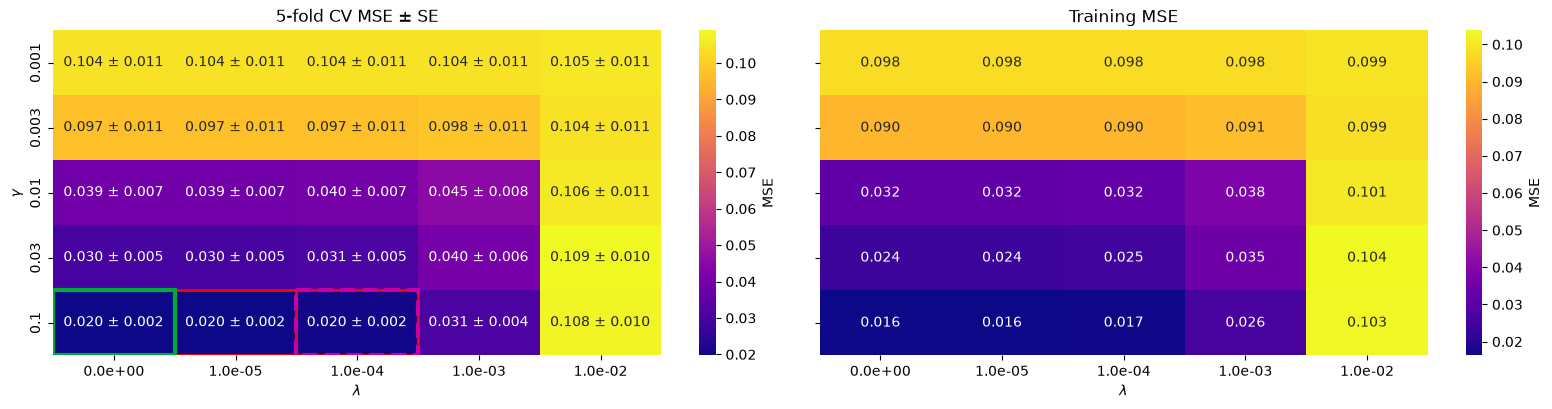

In [55]:
import seaborn as sea 

param_grid = {"neuralnetregressor__gamma": [0.001, 0.003, 0.01, 0.03, 0.1],
              "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-4, 1e-3, 1e-2]}
search = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1, refit=True)
fit_NN = search.fit(X, y)
results = search.cv_results_          # a dict of arrays, one entry per grid point
mse = -results["mean_test_score"].reshape(5, 5)
se = results["std_test_score"].reshape(5, 5) / np.sqrt(cv.get_n_splits() - 1)

train_mse = -results['mean_train_score'].reshape(5, 5)

#Save lambda and gamma lists as their own params 
lambas = param_grid["neuralnetregressor__lmbd"]
gammas = param_grid["neuralnetregressor__gamma"]

#Find minimums and mark for values within the std of this minimum
i_min, j_min = np.unravel_index(np.argmin(mse), mse.shape)
mse_and_std = mse[i_min, j_min] + se[i_min, j_min]
within = mse <= mse_and_std

#one standard error rule
#start from highest lambda
for j in reversed(range(len(lambas))):
    if within[:, j].any():
        i = np.argmin(np.where(within[:, j], mse[:, j], np.inf)) #LLM Assisted
        i_oser, j_oser = i, j
        break

#labels for heatmap
labels = np.array([[rf'{mse[i, j]:.3f} $\pm$ {se[i, j]:.3f}' 
                    for j in range(len(lambas))]
                    for i in range (len(gammas))])

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
sea.heatmap(mse, ax=axes[0], annot=labels, fmt='', cmap='plasma', 
            xticklabels=[f'{lmb:.1e}' for lmb in lambas],
            yticklabels=[f'{gam:g}' for gam in gammas],
            cbar_kws={'label': 'MSE'})
axes[0].set_title(r'5-fold CV MSE $\pm$ SE')
axes[0].set_ylabel(r'$\gamma$')

#LLM Assisted
for i, j in zip(*np.where(within)):
    #border for each val within the std of the minimum
    axes[0].add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="#FF0000", lw=2))

#border around min
axes[0].add_patch(plt.Rectangle((j_min, i_min), 1, 1, fill=False, edgecolor="#00AA39", lw=3))
#border around one standard error rule
axes[0].add_patch(plt.Rectangle((j_oser, i_oser), 1, 1, fill=False, edgecolor="#C9009D", lw=3, ls='--'))   

sea.heatmap(train_mse, ax=axes[1], annot=True, fmt='.3f', cmap='plasma',
            xticklabels=[f'{lmb:.1e}' for lmb in lambas], 
            yticklabels=[f'{gam:g}' for gam in gammas],
            cbar_kws={'label': 'MSE'})
axes[1].set_title('Training MSE')

fig.tight_layout()
for ax in axes:
    ax.set_xlabel(r'$\lambda$')
    
plt.show()

Boxes with red border show if they're within one std of the minimum, green shows the lowest mse and the pink with the dashed line displays the one-standard-error choice. 

From the heatmap we can see that the lowest mse is for $\lambda$ = 0.0 and $\gamma$ = 0.1, whereas both $\lambda$ = 1e-05 and 1e-04 with the same $\gamma$ are within the std of the lowest mse. By following the one-standard-error rule, we choose the $\gamma$ = 0.1 and $\lambda$ = 1e-04 as the best hyperparameters since these are the most regularised.

### c) Architecture (optional)

Optional here and in Project 2 — the example shows how the architecture is
cross-validated with the same tools. With the $(\gamma,\lambda)$ of b), use `validation_curve` (one parameter,
a range of values, the same `cv`) over the number of hidden units
$\{5, 10, 25, 50, 100\}$ for one hidden layer, and `GridSearchCV` over
`hidden` $\in\{(25,), (25, 25), (25, 25, 25)\}$ for the depth. Plot CV and
training MSE against the number of parameters with error bars. Where does
the training MSE keep falling while the CV MSE does not — and what is that
called (Section 2.10)? Project 2 asks for one and two hidden layers with 50
and 100 nodes: are they distinguishable within the error bars?

In [56]:
# train_scores, val_scores = validation_curve(net, X, y, param_name="neuralnetregressor__hidden",
#                                             param_range=[(5,), (10,), (25,), (50,), (100,)],
#                                             cv=cv, scoring="neg_mean_squared_error")
...

Ellipsis

### d) Epochs, chosen by early stopping (optional)

Optional here and in Project 2. The number of epochs is a hyperparameter. The cheap way with
`scikit-learn` is `validation_curve` over `epochs`
$\in\{50, 100, 200, 500, 1000, 2000\}$ — every value retrains from scratch,
which on 100 points costs seconds. Plot the five per-fold validation curves
and their mean against the number of epochs and choose the number at the
minimum of the mean. How much does the location of the minimum vary between
folds? (If your own `fit` records the validation error after every epoch
you can get the whole curve from one training run per fold — that is how it
is done when training is expensive, and it is worth implementing if you
choose to tune the epochs in Project 2.)

In [57]:
...

Ellipsis

### e) The benchmark: OLS and Ridge on the same folds

Cross-validate `make_pipeline(StandardScaler(), PolynomialFeatures(degree),
LinearRegression())` over degrees $1,\dots,15$ and the Ridge version over
degree and $\lambda$ with `GridSearchCV` on the *same* `cv` object. Put the
best polynomial model and the best network (the one chosen in b), or in
c)–d) if you did them) in one table: CV MSE $\pm$
standard error, number of parameters, fitting time (`cv_results_` has
`mean_fit_time`). Does the network beat the polynomial, and is the
difference larger than the error bars? (Section 8.14 of the notes and the
"What you should take away" list of Project 2 say what to expect.)

In [ ]:
import pandas as pd

rng = np.random.default_rng(2026)
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)

# OLS
# hyperparams: degrees
poly = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
search_OLS = GridSearchCV(poly, {"polynomialfeatures__degree": range(1, 16)}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, refit=True)
fit_OLS = search_OLS.fit(X, y)

# RIDGE 
# hyperparams: degrees, penalty 
poly = make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge())
search_ridge = GridSearchCV(poly, {"polynomialfeatures__degree": range(1, 16),
                                        "ridge__alpha": np.logspace(-4,1,10)},
                                  cv=cv, scoring="neg_mean_squared_error", return_train_score=True, refit=True)
fit_Ridge = search_ridge.fit(X, y)



# table setup 

# x               |  best polynomial model ols | --:-- ridge | best network
# CV mse +-std    |
# fitting time +- |
# penalty         |
# gamma           |

def cv_summary(model_name, fitted_search):
    """ Gathers out useful info formatted in a dictionary. LLM assisted """
    results = fitted_search.cv_results_
    index = fitted_search.best_index_
    params = results["params"][index]

    settings = ", ".join(
        f"{key.rsplit('__', 1)[-1]}={value:g}"
        for key, value in params.items()
    )

    # Convert sklearn's fold standard deviation (ddof=0) to the SE
    # formula used in this notebook.
    se = results["std_test_score"][index] / np.sqrt(
        fitted_search.n_splits_ - 1
    )

    return {
        "Model": model_name,
        "Best settings": settings,
        "CV MSE ± SE": (
            f"{-results['mean_test_score'][index]:.4f} ± {se:.4f}"
        ),
        "Fit time mean ± SD (s)": (
            f"{results['mean_fit_time'][index]:.3f} ± "
            f"{results['std_fit_time'][index]:.3f}"
        ),
    }


rows = [
    cv_summary("OLS", fit_OLS),
    cv_summary("Ridge", fit_Ridge),
    cv_summary("Neural network", fit_NN),
]

display(pd.DataFrame(rows).set_index("Model"))

,Best settings,CV MSE ± SE,Fit time mean ± SD (s)
Model,,,
OLS,degree=11,0.0211 ± 0.0032,0.002 ± 0.000
Ridge,"degree=11, alpha=0.00464159",0.0206 ± 0.0026,0.002 ± 0.000
Neural network,"gamma=0.1, lmbd=0",0.0197 ± 0.0019,4.063 ± 0.098


As we see on the table above, the Neural network MSE beats the Ridge and OLS estimators, but all errors fall within each other. When considering the fit time, the linear regressors are far superior. Just with two-dimentional functions, the advantage of using NNs are minimal. 

### f) The test set, once

Generate a fresh test set of 100 points with a different seed and the same
noise. `search.best_estimator_` is the chosen network retrained on all 100
training points (that is what `refit=True` did); report its test MSE
*once*, next to the cross-validated estimate and its standard error, and do
the same for the polynomial model. Are the test MSEs inside the CV error
bars? Should they be — what does the CV estimate describe, and what does
the test MSE describe (exercise 1a)?

In [67]:
rng_test = np.random.default_rng(1)
x_test = np.sort(rng_test.uniform(-1.0, 1.0, 100))
y_test = runge(x_test) + rng_test.normal(0.0, sigma, 100)
X_test = x_test.reshape(-1, 1)

refitted_NN = fit_NN.best_estimator_
mse_test_NN = np.mean((refitted_NN.predict(X_test) - y_test) ** 2)
print(f"Refitted Neural network test MSE: {mse_test_NN:.4f} ± {mse_test_NN/np.sqrt(5-1):4f}")

nn_ = cv_summary("Neural network", fit_NN)

print(f"Neural network CV MSE: " +nn_['CV MSE ± SE'])


Refitted Neural network test MSE: 0.0121 ± 0.006061
Neural network CV MSE: 0.0161 ± 0.0013


The test MSE is outside of the CV MSE. This can be expected as we are using a different seed and the training set is larger. The CV estimate describes the spread of the MSE over 5 folds, where each is split into smaller datasets. The CV MSE is trained on less data but more times, so we have some spread. It therefore makes sense that both the CV MSE and its std is larger than for the test case. 
The overall test MSE describes how well the model fits to the original points. For NNs, its not unreasonble that the test MSE is smaller than the CV MSE.

## Exercise 3 (optional): the MNIST classifier of Project 2, part e)

The same wrapper with `ClassifierMixin` instead of `RegressorMixin`:
`fit(X, y)` takes integer labels (one-hot encode them inside `fit`, and set
`self.classes_ = np.unique(y)`), `predict(X)` returns the integer labels
(`np.argmax` of the softmax output) and `predict_proba(X)` the class
probabilities. Use a **stratified subset of 10 000 training images** (1000
per digit) for everything but the last step, `StratifiedKFold(5,
shuffle=True, random_state=2026)` so that every fold has every digit in the
right proportion, and the metric functions of week 43.

**a)** `GridSearchCV` over hidden units $\{32, 64, 128\}$ and learning
rates $\{0.01, 0.03, 0.1\}$ at a fixed number of epochs, `scoring="accuracy"`.
Report CV accuracy $\pm$ standard error and training accuracy for every
cell; which cells are indistinguishable within the error bars? Apply the
one-standard-error rule towards the *smaller* network.

**b)** `cross_val_predict(best, X_sub, y_sub, cv=cv)` gives the
*out-of-fold* prediction of every image — each predicted by a network that
never saw it. Build the $10\times10$ confusion matrix of these predictions
and compare it with the matrix on the official test set (trained on the same
subset). Are the same digit pairs confused? Which matrix belongs in the
report, and why?

**c)** `learning_curve(best, X_sub, y_sub, train_sizes=[1000, 2000, 5000,
8000], cv=cv)`: CV and training accuracy against the training-set size with
error bars. Is the gap closing? Does more data or a larger network look like
the bottleneck, and what do you expect from the full 60 000 images?

**d)** Train the chosen configuration on the full training set and report
the test accuracy with its standard error $\sqrt{\hat p(1-\hat p)/n}$ and
the test confusion matrix, once, as Project 2 asks.

In [ ]:
class NeuralNetClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=(64,), activation="relu", gamma=0.1, lmbd=0.0, epochs=20, batch_size=100, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        ...
        return self

    def predict_proba(self, X):
        ...

    def predict(self, X):
        ...


# data = np.load("mnist.npz")               # see Project 2 for where to get it
# x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
# y_train = data["y_train"]
# rng = np.random.default_rng(2026)
# sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
# X_sub, y_sub = x_train[sub], y_train[sub]
# cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
...

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| What does the $k$-fold CV error estimate? | The expected error of the *training procedure* on unseen data, with training sets of size $n(k-1)/k$ — not the error of the one network you train at the end. |
| Why does the scaler go inside the fold, and how does a `Pipeline` guarantee it? | Fitting it on all the data leaks the validation part's mean and variance into training; a `Pipeline` refits every step on the training part of each fold. |
| What is wrong with "the best learning rate is 0.01, test MSE 0.0094"? | The learning rate was chosen on the test set, so the test MSE no longer estimates anything; choose by CV, then test once. |
| How many numbers does a CV give, and what do you report? | $k$ validation errors: their mean, their standard error $s/\sqrt{k}$ (optimistic, since the folds overlap), and the training error next to them; `std_test_score` is the fold standard deviation (`ddof=0`), not the standard error. |
| What does the one-standard-error rule do? | Among configurations within one standard error of the best, take the simplest (most regularised, fewest units): the data cannot tell them apart. |
| Is the number of epochs a hyperparameter? | Yes: early stopping chooses it at the minimum of the validation curve; the training curve only falls and says nothing. |
| What must a class provide to be a scikit-learn estimator? | An `__init__` that only stores its keyword arguments under the same names, a `fit` that returns `self`, and `predict` (plus `predict_proba` for a classifier); `BaseEstimator` supplies `get_params`/`set_params`, and `clone` gives every fold a fresh copy. |
| What is `best_estimator_`? | The best grid point retrained on all the training data (`refit=True`) — the model to evaluate on the test set, once. |
| What is an out-of-fold prediction, and why build a confusion matrix from it? | Every sample predicted by a model that did not see it (`cross_val_predict`); the matrix then uses all the training data for evaluation and leaves the test set untouched. |
| Why is the best CV score of a grid optimistic? | The minimum of many noisy estimates is biased downward; the test set used once (or nested CV) removes the bias. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 30 at midnight**. Exercises 1 and 2 are required, except
parts 2c and 2d (architecture and epochs), which are optional; exercises 3
and 4 are optional. Collaboration is encouraged — list your collaborators.
The cross-validation of the learning rate and the penalty in exercise 2 —
the table, the heat map and the test number — is what Project 2 (deadline
**November 6**) requires; cross-validating the depth, the number of nodes
and the epochs is optional there as well. Write the results so that they
can go into the report as they are.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

Tools used: Claude. Model: Opus 5.5, effort: Medium
            Copilot. Model: GPT-6 Luna

What they were used for: 
- Debugging the wrapper exercise from 2a after implementing own code from Project 2. 
- Helping with the shapes of the network input size in this weekly exercise compared to what we've used it for in Project 2 so far.
- Converted output from 2a into a table in markdown
- Helped with shapes of arrays when deriving one-standard-error rule and helped with comprehending what the one-standard-error rule is and why it's useful
- Assisted with cv_summary 

What was done without them: 
- All written text.
- All code unless LLM Assisted is stated. Most of the code comes from Project 2.

---

## Exercise 4 (optional): cross-validation written by hand, and checked against scikit-learn

**The exercise.** Write your own `kfold_indices(n, k, rng)` returning $k$
pairs of (training, validation) index arrays, and a loop that, for every
pair, fits the scaler on the training part, trains your network, and
records the validation MSE; check that `mean` and standard error agree with
`cross_validate` on the same index pairs (pass your list of pairs as
`cv=`). Try it before reading on — the rest of this section is the worked
solution, and you may hand it in if you did the exercise.

Everything `scikit-learn` did above is thirty lines of NumPy. We write them
here — the fold indices, the stratified version, the loop with the scaler
fitted inside each fold — and check at every step that the hand-written loop
and `scikit-learn` give the *same* numbers: first on ordinary least squares,
where the fit is deterministic, then on the week-41 network wrapped as the
estimator of exercise 2a. Knowing what the library does is what lets you
read `cv_results_` without guessing, and it is what you will need the day a
problem does not fit the library's assumptions (grouped samples, time
series, a model that must be trained once and evaluated at every epoch).

### The fold indices

`kfold_indices` shuffles $0,\dots,n-1$ once and cuts the permutation into
$k$ nearly equal validation parts, so every sample is validated exactly
once; `stratified_kfold_indices` does the same within each class, so every
fold carries the class proportions of the whole set. The pairs are checked
against `KFold` and `StratifiedKFold`: with the same shuffled permutation
the fold sizes agree, and with `shuffle=False` on an already shuffled array
the index sets agree exactly.

In [ ]:
def kfold_indices(n, k, rng):
    """k (train_idx, val_idx) pairs: a shuffled range(n) cut into k nearly equal validation parts."""
    perm = rng.permutation(n)
    sizes = np.full(k, n // k)
    sizes[:n % k] += 1                       # the first n % k folds get one extra sample, as KFold does
    bounds = np.r_[0, np.cumsum(sizes)]
    folds = []
    for i in range(k):
        val = perm[bounds[i]:bounds[i + 1]]
        train = np.concatenate([perm[:bounds[i]], perm[bounds[i + 1]:]])
        folds.append((train, val))
    return folds


def stratified_kfold_indices(y, k, rng):
    """As kfold_indices, but each class is cut into k parts separately, so every fold has the class proportions of y."""
    y = np.asarray(y)
    val_parts = [[] for _ in range(k)]
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        for i, part in enumerate(np.array_split(idx, k)):
            val_parts[i].append(part)
    folds = []
    for i in range(k):
        val = np.concatenate(val_parts[i])
        train = np.setdiff1d(np.arange(len(y)), val)
        folds.append((train, val))
    return folds


# checks against scikit-learn
n, k = 100, 5
folds = kfold_indices(n, k, np.random.default_rng(2026))
covered = np.sort(np.concatenate([val for _, val in folds]))
print("every index validated exactly once:", np.array_equal(covered, np.arange(n)),
      "; fold sizes", [len(val) for _, val in folds],
      "; KFold sizes", [len(val) for _, val in KFold(k, shuffle=True, random_state=2026).split(np.zeros(n))])
# with shuffle=False, KFold cuts range(n) in order; feeding it our permutation reproduces our folds exactly
perm = np.random.default_rng(2026).permutation(n)
same = all(np.array_equal(perm[v_sk], v_ours) for (_, v_sk), (_, v_ours) in zip(KFold(k).split(np.zeros(n)), folds))
print("identical to KFold(shuffle=False) applied to the same permutation:", same)

y_cls = np.repeat(np.arange(3), [50, 30, 20])          # an imbalanced three-class toy label vector
sfolds = stratified_kfold_indices(y_cls, k, np.random.default_rng(2026))
print("class counts per validation fold (ours):   ", [np.bincount(y_cls[val], minlength=3).tolist() for _, val in sfolds])
print("class counts per validation fold (sklearn):", [np.bincount(y_cls[val], minlength=3).tolist()
                                                     for _, val in StratifiedKFold(k, shuffle=True, random_state=2026).split(np.zeros(len(y_cls)), y_cls)])

### The loop

`cross_validate` takes a `fit_predict(X_tr, y_tr, X_val)` function — train
from scratch on the training part, return predictions on the validation
part — and does the rest: for every fold it fits a scaler on the training
part only, transforms both parts, calls `fit_predict`, and scores the
validation and the training predictions. The two arrays it returns are what
`scikit-learn` stores as `test_score` and `train_score`.

In [ ]:
def cross_validate_by_hand(fit_predict, X, y, folds, score, scale=True):
    """One validation score and one training score per fold; the scaler is fitted on the training part of each fold only."""
    val_scores, train_scores = [], []
    for train_idx, val_idx in folds:
        X_tr, X_val = X[train_idx], X[val_idx]
        if scale:
            mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)        # fitted on the training part ...
            X_tr, X_val = (X_tr - mean) / std, (X_val - mean) / std   # ... applied to both
        pred_val, pred_tr = fit_predict(X_tr, y[train_idx], X_val, X_tr)
        val_scores.append(score(y[val_idx], pred_val))
        train_scores.append(score(y[train_idx], pred_tr))
    return np.array(val_scores), np.array(train_scores)


def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


def summarise(name, val, train):
    print(f"{name:32s} CV MSE {val.mean():.5f} +/- {val.std(ddof=1) / np.sqrt(len(val)):.5f}   training MSE {train.mean():.5f}   folds {np.round(val, 5)}")

### Check 1: ordinary least squares, where nothing is random

Degree-5 polynomial regression on the Runge data of Project 2, by hand
(`np.linalg.pinv` on the Vandermonde matrix of the *scaled* input) and by
`scikit-learn` (`Pipeline(StandardScaler, PolynomialFeatures,
LinearRegression)`), with the same five folds — our index pairs are passed
to `cross_val_score` as `cv=folds`, which `scikit-learn` accepts. The two
must agree to every digit, and they do.

In [ ]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)
x = np.sort(rng.uniform(-1.0, 1.0, 100))
y = runge(x) + rng.normal(0.0, 0.1, 100)
X = x.reshape(-1, 1)
folds = kfold_indices(len(y), 5, np.random.default_rng(2026))


def fit_predict_ols(X_tr, y_tr, X_val, X_tr_again, degree=5):
    V = lambda Z: np.vander(Z[:, 0], degree + 1, increasing=True)       # 1, x, ..., x^degree of the scaled x
    theta = np.linalg.pinv(V(X_tr)) @ y_tr
    return V(X_val) @ theta, V(X_tr_again) @ theta


val_s, train_s = cross_validate_by_hand(fit_predict_ols, X, y, folds, mse)
summarise("OLS degree 5, by hand", val_s, train_s)
pipe = make_pipeline(StandardScaler(), PolynomialFeatures(5), LinearRegression())
res = cross_validate(pipe, X, y, cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
summarise("OLS degree 5, scikit-learn", -res["test_score"], -res["train_score"])
print("identical:", np.allclose(val_s, -res["test_score"]) and np.allclose(train_s, -res["train_score"]))

### Check 2: the week-41 network as the estimator of exercise 2a

The same loop around a network. The cell below is the week-41 code of the
lecture notebooks (`create_layers`, `feed_forward`, `backpropagation`,
`train`, `predict`); the wrapper after it is exercise 2a filled in for that
code — `fit` builds the layers from the seed and trains, `predict` runs the
forward pass. A fresh initialisation with the same seed in every fold makes
the training deterministic, so the hand-written loop and
`cross_val_score` on the pipeline must agree to every digit; they do. The
network is a $1\to50\to1$ sigmoid network trained with SGD for 1000 epochs
at $\gamma=0.03$, deliberately *not* tuned — tuning it is your exercise 2.

In [ ]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


In [ ]:
class Week41Regressor(BaseEstimator, RegressorMixin):
    """Exercise 2a, filled in for the week-41 code."""

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0, epochs=1000, batch_size=10, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        sizes = [X.shape[1], *self.hidden, 1]
        layers = create_layers(sizes, self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train(X, y.reshape(-1, 1), layers, self.activation, "mse", gamma=self.gamma,
                                            epochs=self.epochs, batch_size=self.batch_size, lmbd2=self.lmbd,
                                            rng=np.random.default_rng(self.seed))
        return self

    def predict(self, X):
        return predict(X, self.layers_, self.activation, "mse")[:, 0]


def fit_predict_net(X_tr, y_tr, X_val, X_tr_again):
    est = Week41Regressor().fit(X_tr, y_tr)
    return est.predict(X_val), est.predict(X_tr_again)


val_s, train_s = cross_validate_by_hand(fit_predict_net, X, y, folds, mse)
summarise("1-50-1 network, by hand", val_s, train_s)
net = make_pipeline(StandardScaler(), Week41Regressor())
res = cross_validate(net, X, y, cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
summarise("1-50-1 network, scikit-learn", -res["test_score"], -res["train_score"])
print("identical:", np.allclose(val_s, -res["test_score"]) and np.allclose(train_s, -res["train_score"]))
print("the untuned network against degree-5 OLS: CV MSE", f"{val_s.mean():.4f}", "vs", f"{-cross_val_score(pipe, X, y, cv=folds, scoring='neg_mean_squared_error').mean():.4f}",
      "-- the noise level is sigma^2 = 0.01")

### A small grid, both ways

Finally the grid search of exercise 2b in miniature — three learning rates,
two penalties — once with two nested loops around `cross_validate_by_hand`
and once with `GridSearchCV`, and the one-standard-error rule applied to
the result. `GridSearchCV` returns exactly the table the loops produce, plus
`best_estimator_`, the winner retrained on all 100 points. One detail
worth knowing: `std_test_score` is the standard deviation over the folds
with `ddof=0`, so the standard error $s/\sqrt{k}$ with the sample standard
deviation $s$ is `std_test_score / np.sqrt(k - 1)`.

In [ ]:
gammas, lambdas = [0.01, 0.03, 0.1], [0.0, 1e-3]
table = np.zeros((len(gammas), len(lambdas)))
table_se = np.zeros_like(table)
for i, g in enumerate(gammas):
    for j, l in enumerate(lambdas):
        fp = lambda X_tr, y_tr, X_val, X_tr2, g=g, l=l: (lambda est: (est.predict(X_val), est.predict(X_tr2)))(Week41Regressor(gamma=g, lmbd=l).fit(X_tr, y_tr))
        v, _ = cross_validate_by_hand(fp, X, y, folds, mse)
        table[i, j], table_se[i, j] = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
print("by hand, CV MSE (rows gamma, columns lambda):\n", np.round(table, 5))

search = GridSearchCV(net, {"week41regressor__gamma": gammas, "week41regressor__lmbd": lambdas},
                      cv=folds, scoring="neg_mean_squared_error", return_train_score=True)
search.fit(X, y)
grid = -search.cv_results_["mean_test_score"].reshape(len(gammas), len(lambdas))
grid_se = search.cv_results_["std_test_score"].reshape(len(gammas), len(lambdas)) / np.sqrt(len(folds) - 1)   # std_test_score has ddof=0
print("GridSearchCV, CV MSE:\n", np.round(grid, 5), "\nidentical:", np.allclose(table, grid) and np.allclose(table_se, grid_se))
print("best:", search.best_params_, f"CV MSE {-search.best_score_:.5f} +/- {grid_se.ravel()[search.best_index_]:.5f}")
within = grid <= grid.min() + grid_se.ravel()[search.best_index_]
print("within one standard error of the best (rows gamma, columns lambda):\n", within)
print("the one-standard-error rule picks the most regularised of these: lambda =", max(l for j, l in enumerate(lambdas) if within[:, j].any()),
      "-- and best_estimator_ is the winner retrained on all 100 points:", type(search.best_estimator_[-1]).__name__,
      search.best_estimator_[-1].get_params())

Six grid points move the network from $0.030$ to $0.023$ — below the
degree-5 polynomial's $0.035$ and within a factor of two of the noise
floor $\sigma^2=0.01$; the rest of the way, with error bars, is
exercise 2.

That is all a cross-validation is: a permutation cut into $k$ pieces, a
scaler fitted $k$ times, a model trained $k$ times from scratch, and $k$
numbers summarised by their mean and standard error. `scikit-learn` adds
the bookkeeping, the parallelism (`n_jobs`), the refit, and — not least —
the guarantee that the scaler never sees the validation fold. Use the
library in Project 2; keep this section for the day you need to know what
it did.